In [2]:
import calendar
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns
import statsmodels.api as sm
import os
import warnings
from coreforecast.scalers import boxcox, boxcox_lambda
from cycler import cycler
from scipy.stats import pearsonr
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from utilsforecast.plotting import plot_series as plot_series_utils

In [3]:
warnings.filterwarnings("ignore")
np.random.seed(1)
random.seed(1)

In [4]:
mpl.colormaps.register(
    mpl.colors.ListedColormap(["#000000", "#D55E00"], name="black_and_orange"),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(["#000000", "#D55E00"], name="black_and_orange"),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#000000"], name="black"),
    force=True,
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#0072B2", "#D55E00"],
        name='black_and_2color',
    ),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#D55E00", "#0072B2", "#009E73"],
        name='black_and_3color',
    ),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#D55E00", "#0072B2", "#009E73", "#CC79A7"],
        name='black_and_4color',
    ),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#D55E00", "#0072B2", "#009E73", "#CC79A7"],
        name='r_colors',
    ),
    force=True
)

In [5]:
df = pd.DataFrame({
    "Year": list(range(2015, 2020)),
    "Observation": [123, 39, 78, 52, 110],
})

In [6]:
print(df.index)
print(df.columns)

RangeIndex(start=0, stop=5, step=1)
Index(['Year', 'Observation'], dtype='str')


In [7]:
year_df = df.set_index("Year")
year_df

,Observation
Year,
2015,123
2016,39
2017,78
2018,52
2019,110


In [10]:
melsyd_economy = (
    pd.read_csv("../data/fppp/ansett.csv", parse_dates=["ds"])
    .loc[lambda x : (x["Airports"] == "MEL-SYD") & (x["Class"]=="Economy")]
    .rename(columns={"Airports" : "Unique_id"})
    .assign(y=lambda x : x["y"]/1000)
)
melsyd_economy.head()

,ds,Unique_id,Class,y
3881,1987-06-22,MEL-SYD,Economy,20.167
3882,1987-06-29,MEL-SYD,Economy,20.161
3883,1987-07-06,MEL-SYD,Economy,19.993
3884,1987-07-13,MEL-SYD,Economy,20.986
3885,1987-07-20,MEL-SYD,Economy,20.497


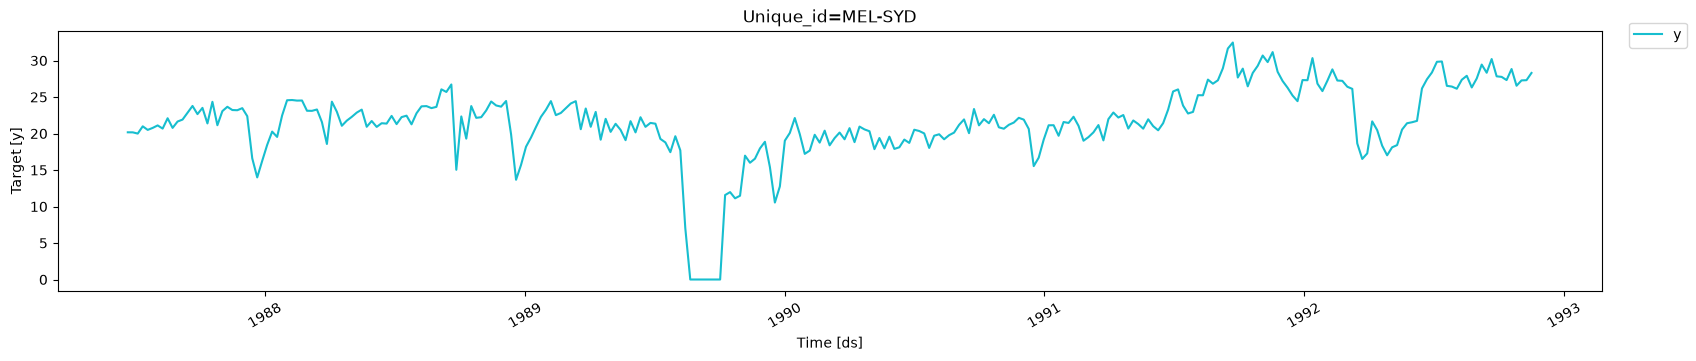

In [14]:
plot_series_utils(df=melsyd_economy, id_col="Unique_id", time_col="ds", target_col="y")

In [5]:
aus_production = pd.read_csv("../data/fppp/aus_production.csv", parse_dates=["ds"])
aus_gas = aus_production[["ds", "Gas"]].rename(columns={"Gas" : "y"}).assign(unique_id="Gas")
y = aus_gas["y"].to_numpy()

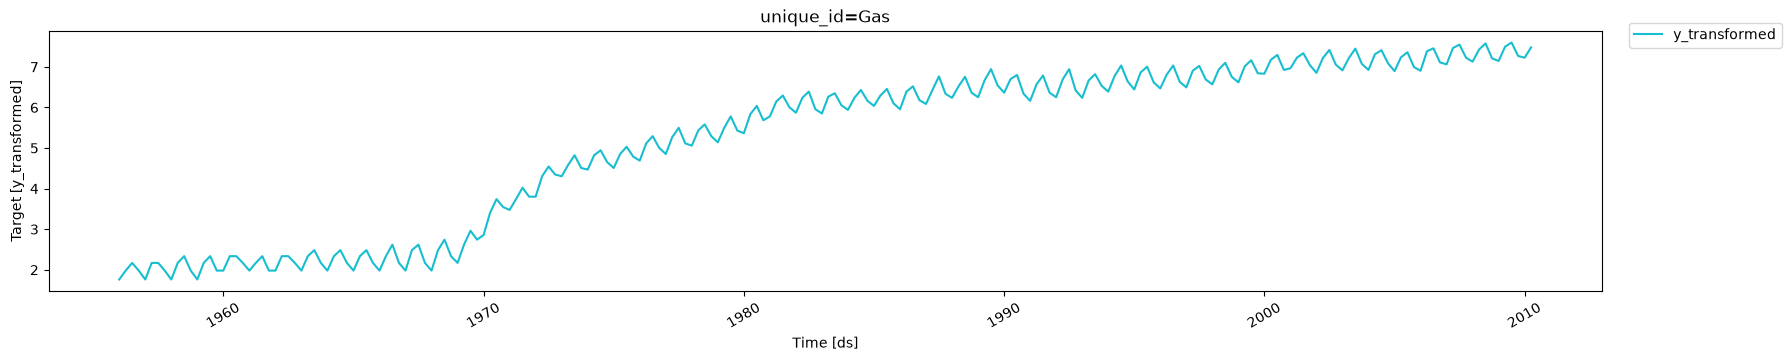

In [11]:
optimal_lambda = boxcox_lambda(y, method="guerrero", season_length=4)
df = aus_gas.assign(y_transformed=boxcox(y,optimal_lambda))
plot_series_utils(df, target_col="y_transformed")